# Diabetes risk prediction: how much does a data-leak flatter the model?
**Pima Indians diabetes data (768 women), repeated cross-validation, and a screening-threshold analysis**

**Summary.** The first version of this project filled missing measurements using the **median of each outcome group** (diabetic / non-diabetic). That uses the answer to build the inputs, and it made random forest and gradient boosting look like 88% accurate models. Imputing properly, inside each cross-validation fold and without looking at the outcome, the same models score **76%**, and a plain logistic regression does as well (77%). Glucose is by far the strongest predictor. At the default cut-off the models miss about 40% of diabetic cases, so I also show how to trade accuracy for sensitivity if the model is used for screening.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from sklearn.inspection import permutation_importance
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.25})
FIG=Path('../figures'); RES=Path('../results'); FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
d=pd.read_csv('../data/pima_diabetes.csv'); y=d.Outcome
print(d.shape,'| duplicates:',int(d.duplicated().sum()),'| diabetic share:',round(y.mean(),3),'| majority baseline accuracy:',round(1-y.mean(),3))
Z=['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
zeros=(d.drop(columns='Outcome')==0).sum(); zeros[zeros>0].to_frame('zeros (impossible values)')

(768, 9) | duplicates: 0 | diabetic share: 0.349 | majority baseline accuracy: 0.651


,zeros (impossible values)
Pregnancies,111
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


## 1. Data
768 women, 8 measurements, 34.9% diabetic. No missing values are flagged, but five measurements contain **zeros that are physically impossible** (a glucose or BMI of 0): glucose 5, BMI 11, blood pressure 35, skin thickness 227 and insulin 374. These are missing values coded as 0. (Zero pregnancies is real and is kept.)

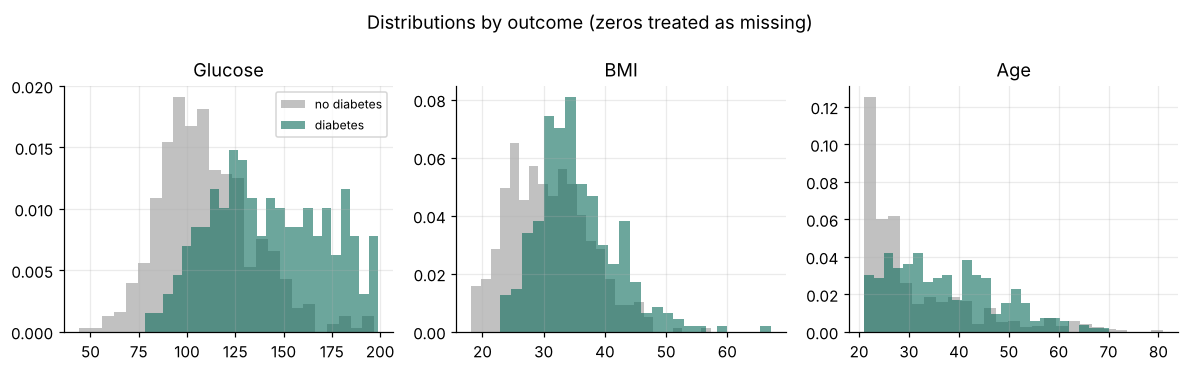

In [2]:
X=d.drop(columns='Outcome').copy(); X[Z]=X[Z].replace(0,np.nan)
fig,axs=plt.subplots(1,3,figsize=(11,3.4))
for ax,c in zip(axs,['Glucose','BMI','Age']):
    for o,col,lab in ((0,'#999999','no diabetes'),(1,'#0b6b5a','diabetes')):
        ax.hist(X.loc[y==o,c].dropna(),bins=25,alpha=.6,color=col,label=lab,density=True)
    ax.set_title(c)
axs[0].legend(fontsize=8); fig.suptitle('Distributions by outcome (zeros treated as missing)'); fig.tight_layout(); fig.savefig(FIG/'01_distributions.png'); plt.show()

## 2. The leak: filling in missing values with the outcome
The original app replaced missing values with the **median of the person's own outcome group** (for example, a missing glucose became 110.6 if the person was non-diabetic and 142.3 if diabetic). Any model can then read the label from the filled-in cell. I compare that to honest imputation (median of the *training* fold only, inside the cross-validation pipeline). Same data, same models, same 25 test folds.

In [3]:
leak=X.copy()
for c in Z:
    for o in (0,1): leak.loc[(y==o)&leak[c].isna(),c]=X.loc[y==o,c].median()   # uses the label: leaky
cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=5,random_state=0)
MODELS={'Logistic regression':lambda:LogisticRegression(max_iter=2000),
        'Random forest':lambda:RandomForestClassifier(300,min_samples_leaf=3,random_state=0,n_jobs=-1),
        'Gradient boosting':lambda:GradientBoostingClassifier(random_state=0)}
SC=['accuracy','balanced_accuracy','recall','roc_auc']; rows=[]
for mn,mk in MODELS.items():
    honest=Pipeline([('i',SimpleImputer(strategy='median')),('s',StandardScaler()),('m',mk())])
    leaky=Pipeline([('s',StandardScaler()),('m',mk())])
    for lab,pipe,data in (('honest (imputed inside CV)',honest,X),('leaky (imputed with the outcome)',leaky,leak)):
        r=cross_validate(pipe,data,y,cv=cv,scoring=SC)
        rows.append({'model':mn,'imputation':lab,'accuracy':r['test_accuracy'].mean(),'accuracy sd':r['test_accuracy'].std(),
                     'balanced accuracy':r['test_balanced_accuracy'].mean(),'sensitivity':r['test_recall'].mean(),'ROC AUC':r['test_roc_auc'].mean()})
R=pd.DataFrame(rows); R.round(3).to_csv(RES/'leak_vs_honest.csv',index=False); R.round(3)

,model,imputation,accuracy,accuracy sd,balanced accuracy,sensitivity,ROC AUC
0,Logistic regression,honest (imputed inside CV),0.768,0.025,0.720,0.563,0.837
1,Logistic regression,leaky (imputed with the outcome),0.775,0.028,0.733,0.596,0.859
2,Random forest,honest (imputed inside CV),0.760,0.030,0.720,0.589,0.835
3,Random forest,leaky (imputed with the outcome),0.879,0.020,0.866,0.822,0.943
4,Gradient boosting,honest (imputed inside CV),0.758,0.030,0.725,0.615,0.829
5,Gradient boosting,leaky (imputed with the outcome),0.880,0.021,0.863,0.807,0.950


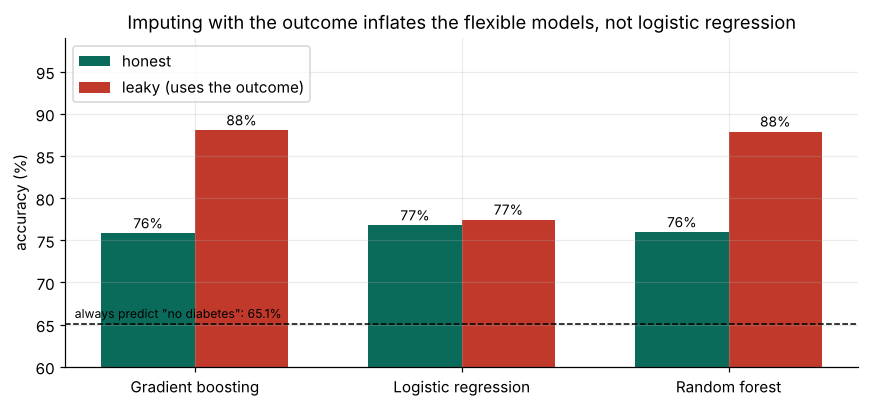

In [4]:
P=R.pivot(index='model',columns='imputation',values='accuracy')[['honest (imputed inside CV)','leaky (imputed with the outcome)']]
fig,ax=plt.subplots(figsize=(8,3.8)); xs=np.arange(len(P)); w=.35
ax.bar(xs-w/2,P.iloc[:,0]*100,w,color='#0b6b5a',label='honest'); ax.bar(xs+w/2,P.iloc[:,1]*100,w,color='#c0392b',label='leaky (uses the outcome)')
for i,(a,b) in enumerate(zip(P.iloc[:,0],P.iloc[:,1])): ax.text(i-w/2,a*100+.6,f'{a*100:.0f}%',ha='center',fontsize=9); ax.text(i+w/2,b*100+.6,f'{b*100:.0f}%',ha='center',fontsize=9)
ax.axhline(65.1,color='k',ls='--',lw=1); ax.text(-.45,65.8,'always predict "no diabetes": 65.1%',fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels(P.index); ax.set_ylim(60,99); ax.set_ylabel('accuracy (%)'); ax.legend(loc='upper left'); ax.set_title('Imputing with the outcome inflates the flexible models, not logistic regression')
fig.tight_layout(); fig.savefig(FIG/'02_leak.png'); plt.show()

**Reading the result.**
- With honest imputation, all three models land at **76-77% accuracy (ROC AUC about 0.83-0.84)** against a 65.1% baseline. The ordering between them is within noise (SD about 3 points).
- With the leaky imputation, random forest and gradient boosting jump to **88%** (AUC 0.94-0.95), because a flexible model can learn that "glucose = 142.3" means diabetic. Logistic regression barely moves because it cannot carve out those exact values.
- So the extra 12 points were never real. A simple logistic regression, the best-calibrated and easiest to explain, is a fine final choice.

out-of-fold ROC AUC: 0.836


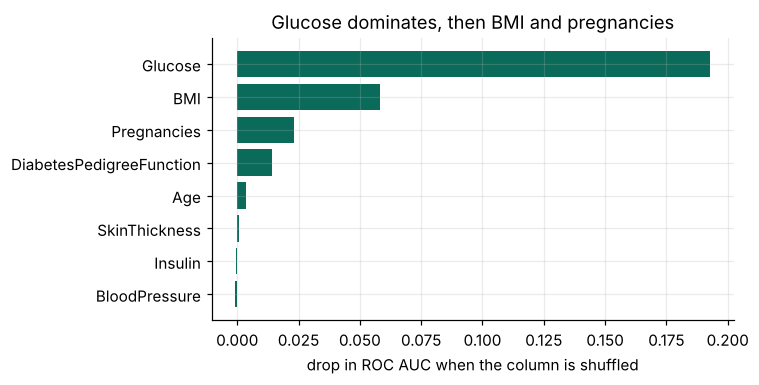

Glucose                     0.193
BMI                         0.058
Pregnancies                 0.023
DiabetesPedigreeFunction    0.014
dtype: float64

In [5]:
# Final model: logistic regression, honest pipeline. Out-of-fold probabilities for error analysis.
final=Pipeline([('i',SimpleImputer(strategy='median')),('s',StandardScaler()),('m',LogisticRegression(max_iter=2000))])
oof=cross_val_predict(final,X,y,cv=StratifiedKFold(5,shuffle=True,random_state=0),method='predict_proba')[:,1]
print('out-of-fold ROC AUC: %.3f'%roc_auc_score(y,oof))
imp=pd.Series(0.0,index=X.columns)
for tr,te in StratifiedKFold(5,shuffle=True,random_state=1).split(X,y):
    m=final.fit(X.iloc[tr],y.iloc[tr]); pi=permutation_importance(m,X.iloc[te],y.iloc[te],scoring='roc_auc',n_repeats=20,random_state=0); imp+=pi.importances_mean/5
imp=imp.sort_values(); imp.sort_values(ascending=False).round(4).to_csv(RES/'permutation_importance.csv',header=['AUC drop when shuffled'])
fig,ax=plt.subplots(figsize=(7,3.6)); ax.barh(imp.index,imp.values,color='#0b6b5a'); ax.set_xlabel('drop in ROC AUC when the column is shuffled'); ax.set_title('Glucose dominates, then BMI and pregnancies'); fig.tight_layout(); fig.savefig(FIG/'03_importance.png'); plt.show()
imp.sort_values(ascending=False).round(3).head(4)

## 3. Using it for screening: choosing a cut-off
At the default 0.5 cut-off the model finds only about 56-60% of diabetic cases. For screening, missing a case is worse than an unnecessary follow-up test, so the cut-off should be lowered. The table shows the trade-off using out-of-fold probabilities (so each person was scored by a model that never saw them).

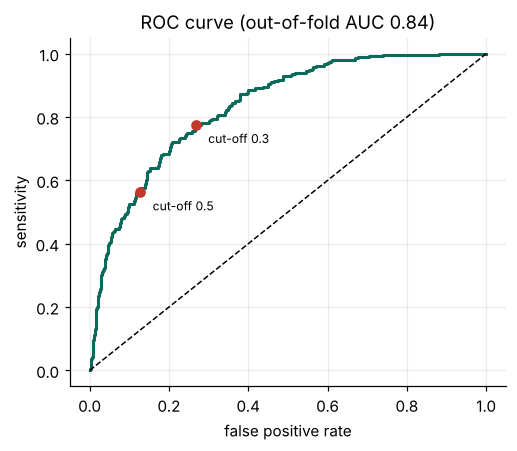

,sensitivity (diabetics found),specificity (healthy cleared),precision (flagged who are diabetic),share flagged,accuracy
cut-off,,,,,
0.50,0.567,0.872,0.704,0.281,0.766
0.40,0.672,0.822,0.669,0.350,0.770
0.35,0.720,0.790,0.648,0.388,0.766
0.30,0.776,0.726,0.603,0.449,0.743
0.25,0.836,0.644,0.557,0.523,0.711


In [6]:
rows=[]
for t in (.5,.4,.35,.3,.25):
    p=(oof>=t).astype(int); tn,fp,fn,tp=confusion_matrix(y,p).ravel()
    rows.append({'cut-off':t,'sensitivity (diabetics found)':tp/(tp+fn),'specificity (healthy cleared)':tn/(tn+fp),'precision (flagged who are diabetic)':tp/(tp+fp),'share flagged':p.mean(),'accuracy':(tp+tn)/len(y)})
T=pd.DataFrame(rows).set_index('cut-off'); T.round(3).to_csv(RES/'threshold_tradeoff.csv'); 
fpr,tpr,thr=roc_curve(y,oof); fig,ax=plt.subplots(figsize=(4.8,4.2)); ax.plot(fpr,tpr,color='#0b6b5a',lw=2); ax.plot([0,1],[0,1],'k--',lw=1)
for t in (.5,.3):
    i=np.argmin(abs(thr-t)); ax.scatter(fpr[i],tpr[i],color='#c0392b',zorder=3); ax.annotate(f'cut-off {t}',(fpr[i],tpr[i]),textcoords='offset points',xytext=(8,-12),fontsize=8)
ax.set_xlabel('false positive rate'); ax.set_ylabel('sensitivity'); ax.set_title(f'ROC curve (out-of-fold AUC {roc_auc_score(y,oof):.2f})'); fig.tight_layout(); fig.savefig(FIG/'04_roc.png'); plt.show()
T.round(3)

Lowering the cut-off from 0.5 to 0.3 raises the share of diabetics found from 57% to 78%, at the price of flagging many more healthy women (precision falls from 70% to 60%, and the share of all women flagged rises from 28% to 45%). Where to set it is a clinical and cost decision, not a statistical one. The cut-offs above are evaluated on the same out-of-fold predictions, so treat the numbers as indicative.

## 4. Conclusions
- Imputing missing values with outcome-specific medians inflated tree-model accuracy from 76% to 88%. The honest figure is 76-77%.
- A logistic regression matches random forest and gradient boosting on this dataset, and is simpler to explain and audit.
- Glucose is the dominant predictor; BMI and number of pregnancies add smaller amounts.
- As a screening aid it needs a lowered cut-off to find most cases, and will then flag many people who do not have diabetes.

**Limitations.** 768 women of Pima Indian heritage aged 21 and over, so the model should not be applied to other groups without re-validation. A third of insulin and skin-thickness readings are missing, which limits what any model can learn. This is a teaching dataset and the notebook is not a clinical tool.